# 2026 DL Lab5: Object Detection on COCO 2017

Before we start, please put **your name** and **SID** in following format: <br>
Hi I'm 陸仁賈, 315831000.

**Your Answer:**    
Hi I'm 王薪愷, 315832002

## Overview

Train a three-scale YOLOv3 detector to locate and classify objects from 20 COCO categories.

Use the training set to learn model parameters and the validation set to select your model.

Implement the detection neck and head in `src/yolo.py`. Do not use COCO-pretrained detectors.

Only weights pretrained through supervised ImageNet classification are allowed.

## Dataset

Download `dataset.zip` and extract it. The dataset ZIP contains:

- `images/`: images for all splits.

- `train.txt`: list for the training set.

- `val.txt`: list for the validation set.

- `test.txt`: list for the test set.

COCO 2017 subset with 20 categories: **10,193 Train**, **3,397 Validation** and **9,060 Test** images.


## Import Packages

In [1]:
import random
from pathlib import Path

import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from torch.amp import autocast, GradScaler
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

from src.config import ANCHORS, CLASS_NAMES, IMG_MEAN, IMG_STD, MODEL_NAME, YOLO_IMG_DIM
from src.dataset import CocoDetectorDataset, collate_fn
from src.evaluate import evaluate
from src.yolo import getODmodel
from src.yolo_loss import YOLOv3Loss

/root/venvs/torch-cu121/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Hyperparameters

In [2]:
# Training settings.
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
num_epochs = 80
image_size = YOLO_IMG_DIM
batch_size = 8
num_workers = 2
learning_rate = 1e-4
weight_decay = 5e-4
eval_interval = 5
use_amp = device.type == "cuda"

# Loss weights.
lambda_coord = 5.0
lambda_obj = 1.0
lambda_noobj = 0.5
lambda_class = 1.0

# Set random seeds.
seed = 2026
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

## Path & Config

In [3]:
# Dataset paths.
data_root = Path("dataset")
train_list_file = data_root / "train.txt"
val_list_file = data_root / "val.txt"

# Model settings and checkpoint paths.
model_name = MODEL_NAME
pretrained = True
checkpoint_dir = Path("checkpoints")
load_network_path = None

## Dataset & DataLoader

`train_loader` and `val_loader` return encoded targets for loss computation.

`eval_loader` returns the original image information needed for COCO evaluation.

In [4]:
# Train
train_dataset = CocoDetectorDataset(
    root=data_root,
    list_file=train_list_file,
    train=True,
    encode_target=True,
    image_size=image_size,
)
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    collate_fn=collate_fn,
    pin_memory=device.type == "cuda",
)

# Validation
val_dataset = CocoDetectorDataset(
    root=data_root,
    list_file=val_list_file,
    train=False,
    encode_target=True,
    image_size=image_size,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    collate_fn=collate_fn,
    pin_memory=device.type == "cuda",
)

print(f"Train: {len(train_dataset):,} images")
print(f"Validation: {len(val_dataset):,} images")
print(f"Classes: {len(CLASS_NAMES)}")

Train: 10,193 images
Validation: 3,397 images
Classes: 20


## Inspect an Annotated Image

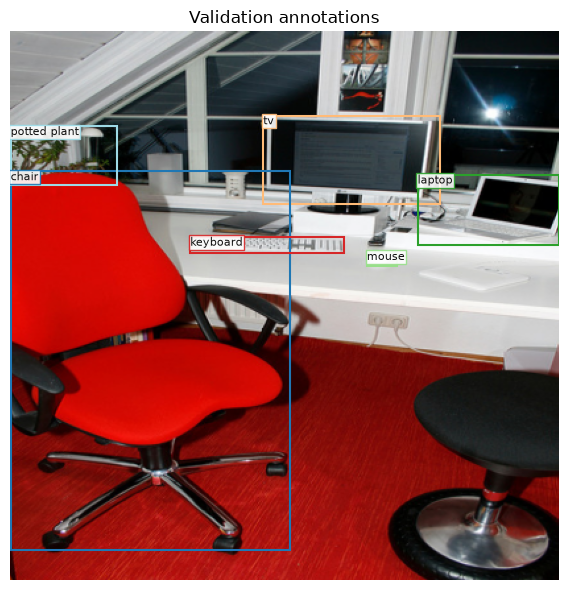

In [5]:
def draw_boxes(axis, image, boxes, labels):
    image_height, image_width = image.shape[:2]
    colors = plt.get_cmap("tab20")
    axis.imshow(image)

    for box, label in zip(boxes, labels):
        # Convert normalized xyxy boxes to pixels for display.
        x1, y1, x2, y2 = box * [image_width, image_height, image_width, image_height]
        color = colors(int(label))
        axis.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor=color,
                linewidth=1.5,
            )
        )
        axis.text(
            x1,
            y1,
            CLASS_NAMES[int(label)],
            fontsize=8,
            color="#111111",
            va="top",
            bbox={"facecolor": "white", "edgecolor": color, "alpha": 0.9, "pad": 1},
            clip_on=True,
        )

    axis.axis("off")


# Undo normalization to display RGB images.
image_tensor, _, example = val_dataset[0]
image_rgb = image_tensor.permute(1, 2, 0).numpy()
image_rgb = (image_rgb * np.array(IMG_STD) + np.array(IMG_MEAN)).clip(0, 1)

figure, axis = plt.subplots(figsize=(9, 6))
draw_boxes(axis, image_rgb, example["boxes"], example["labels"])
for x1, y1, x2, y2 in example["crowd_boxes"] * image_rgb.shape[0]:
    axis.add_patch(
        Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="#444444",
            linestyle="--",
            linewidth=2,
        )
    )
axis.set_title("Validation annotations")
figure.tight_layout()
plt.show()
plt.close(figure)

## Load Model

The backbone provides stride 32/16/8 feature maps.

The detection head returns `(N, 13, 13, 75)`, `(N, 26, 26, 75)` and `(N, 52, 52, 75)` predictions, where `75 = 3 × (5 + 20)`.

Set `load_network_path` to load model weights. This initializes model parameters.

In [6]:
model = getODmodel(
    pretrained=pretrained and load_network_path is None,
    model_name=model_name,
).to(device)

if load_network_path is not None:
    state_dict = torch.load(load_network_path, map_location="cpu", weights_only=True)
    model.load_state_dict(state_dict)

print(f"Device: {device}")
print(f"Backbone: {model_name}")
print(f"Parameters: {sum(parameter.numel() for parameter in model.parameters()):,}")

Device: cuda:0
Backbone: convnext_large.fb_in1k
Parameters: 217,612,449


## Loss, Optimizer & Scheduler

Each target contains `[tx, ty, w, h, obj, one-hot classes]`. 

The loss combines GIoU localization, focal objectness, and cross-entropy classification.

In [7]:
# Create the loss function.
criterion = YOLOv3Loss(
    lambda_coord=lambda_coord,
    lambda_obj=lambda_obj,
    lambda_noobj=lambda_noobj,
    lambda_class=lambda_class,
    anchors=ANCHORS,
).to(device)

# AdamW optimizer and cosine learning-rate schedule.
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay,
)
lr_scheduler = CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-6)
scaler = GradScaler("cuda", enabled=use_amp)

## Training Loop

Train on the full training set and compute validation loss after every epoch.

Save the best model according to validation loss, and evaluate COCO bbox AP every `eval_interval` epochs.

- `best_detector.pth` contains the best model weights.

- `detector.pth` contains the latest model weights.

In [ ]:
checkpoint_dir.mkdir(parents=True, exist_ok=True)
best_val_loss = float("inf")
history = []

for epoch in range(num_epochs):
    # Training
    model.train()
    train_loss = 0.0
    train_images = 0
    current_lr = optimizer.param_groups[0]["lr"]
    progress = tqdm(train_loader, desc=f"Train {epoch + 1}/{num_epochs}", leave=False)

    for images, targets, _ in progress:
        images = images.to(device, non_blocking=True)
        targets = [target.to(device, non_blocking=True) for target in targets]
        optimizer.zero_grad(set_to_none=True)

        with autocast(device.type, enabled=use_amp):
            predictions = model(images)

        loss_dict = criterion(predictions, targets)
        if not torch.isfinite(loss_dict["total"]):
            raise FloatingPointError("Training loss is not finite.")

        scaler.scale(loss_dict["total"]).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss_dict["total"].detach().item() * len(images)
        train_images += len(images)
        progress.set_postfix(loss=f"{train_loss / train_images:.4f}")

    train_loss /= train_images
    lr_scheduler.step()

    # Validation
    model.eval()
    val_loss = 0.0
    val_images = 0

    with torch.no_grad():
        for images, targets, _ in val_loader:
            images = images.to(device, non_blocking=True)
            targets = [target.to(device, non_blocking=True) for target in targets]

            predictions = model(images)
            loss_dict = criterion(predictions, targets)
            if not torch.isfinite(loss_dict["total"]):
                raise FloatingPointError("Validation loss is not finite.")

            val_loss += loss_dict["total"].item() * len(images)
            val_images += len(images)

    val_loss /= val_images
    history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss})
    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f} | LR: {current_lr:.6f}"
    )

    # Save the latest weights and a separate copy when validation loss improves.
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), checkpoint_dir / "best_detector.pth")
    torch.save(model.state_dict(), checkpoint_dir / "detector.pth")

    # Compute validation AP in original coordinates with the official COCO evaluator.
    if (epoch + 1) % eval_interval == 0 or epoch + 1 == num_epochs:
        metrics = evaluate(
            model,
            val_loader,
            annotation_data=val_dataset.coco,
            category_ids=val_dataset.category_ids,
        )
        print(f"Validation AP: {metrics['AP']:.4f} | AP50: {metrics['AP50']:.4f}")


Epoch 1/80 | Train loss: 4.2900 | Val loss: 3.3524 | LR: 0.000100


Epoch 2/80 | Train loss: 3.1047 | Val loss: 2.9003 | LR: 0.000100


Epoch 3/80 | Train loss: 2.6267 | Val loss: 2.6934 | LR: 0.000100


Epoch 4/80 | Train loss: 2.2981 | Val loss: 2.5609 | LR: 0.000100


Epoch 5/80 | Train loss: 2.0738 | Val loss: 2.5316 | LR: 0.000099


creating index...
index created!
Loading and preparing results...
DONE (t=1.06s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=16.56s).
Accumulating evaluation results...
DONE (t=4.06s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.072
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.216
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.028
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.030
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.087
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.120
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.111
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.198
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.220
 Average Recall     (AR) @[ IoU=0.

... (83 outputs left out)

creating index...
index created!
Loading and preparing results...
DONE (t=1.12s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=16.77s).
Accumulating evaluation results...
DONE (t=4.61s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.167
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.331
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.154
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.051
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.198
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.347
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.217
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.330
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.349
 Average Recall     (AR) @[ IoU=0.

Epoch 76/80 | Train loss: 0.1725 | Val loss: 2.7436 | LR: 0.000002


Epoch 77/80 | Train loss: 0.1711 | Val loss: 2.7492 | LR: 0.000002


Epoch 78/80 | Train loss: 0.1705 | Val loss: 2.7534 | LR: 0.000001


## Kaggle Submission

Load a trained checkpoint and generate `result.csv` for all Test images.

Predictions use original-image coordinates, class-wise NMS, and at most 100 boxes per image.

In [ ]:
from src.predict_test import predict_test

result_path = predict_test(
    weights_path=checkpoint_dir / "best_detector.pth",
    data_root=data_root,
    output_path=Path("result.csv"),
    batch_size=batch_size,
    device=device,
    model_name=model_name,
    image_size=image_size,
)

Predict test: 100%|██████████| 1133/1133 [22:32<00:00,  1.19s/it]

Wrote 9,060 images to result.csv
